# Module 6 Lab 3: Textbook Appendix C, Retrieve and Search
Reproduce the book’s retrieval patterns on your table: a filtered SELECT with WHERE, an ORDER BY, and a text search using LIKE with wildcards (for example, every customer whose name contains a chosen letter pair). Finish by pulling one query’s result into pandas and charting it.

In [12]:
import pandas as pd
import sqlite3

# connect to database
con = sqlite3.connect("module6lab2.db")

In [13]:
# filtered select with where
query_filter = """
SELECT *
FROM customers
WHERE Income > 85000
ORDER BY Income DESC;
"""
print("High Income Earners")
print(pd.read_sql(query_filter, con))

High Income Earners
   ID      Name           City  Income
0   8   Jessica  Redondo Beach  105000
1   4    Alexis       Torrance  100000
2   6      Flor  Redondo Beach   95000
3   3  Chauncey      Inglewood   90000
4   7     Cinda    Los Angeles   89000


In [14]:
# order by income query
query_orderby = """
SELECT *
FROM customers
ORDER BY Income DESC;
"""

print("Customers Ordered by Income")
print(pd.read_sql(query_orderby, con))

Customers Ordered by Income
   ID      Name           City  Income
0   8   Jessica  Redondo Beach  105000
1   4    Alexis       Torrance  100000
2   6      Flor  Redondo Beach   95000
3   3  Chauncey      Inglewood   90000
4   7     Cinda    Los Angeles   89000
5   1   Bentlei      Inglewood   85000
6   2    Harlei      Hawthorne   85000
7   5    Summer       Torrance   80000


In [16]:
# Text search using like with wildcards
query_like = """
SELECT *
FROM customers
WHERE Name LIKE '%ei%';
"""

print("Customers with 'ei' in their name")
print(pd.read_sql(query_like, con))

Customers with 'ei' in their name
   ID     Name       City  Income
0   1  Bentlei  Inglewood   85000
1   2   Harlei  Hawthorne   85000


Text(0, 0.5, 'Average Income')

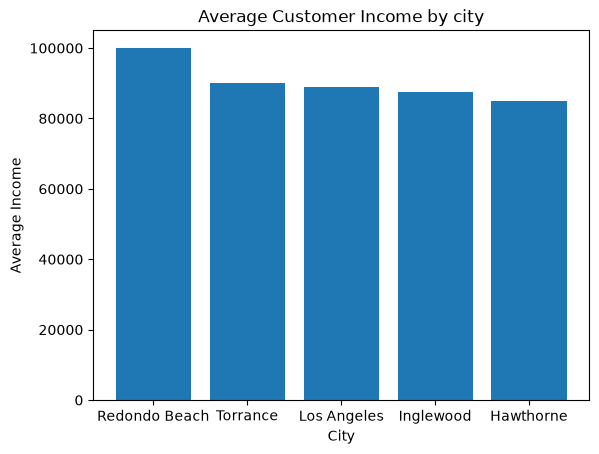

In [21]:
# Pulling result and charting it
import matplotlib.pyplot as plt
query_chart= """
SELECT City, AVG(Income) AS Avg_Income
FROM customers
GROUP BY City
ORDER BY Avg_Income DESC;
"""
chart_data = pd.read_sql(query_chart, con)

# Create bar chart
plt.bar(chart_data['City'], chart_data['Avg_Income'])
plt.title ("Average Customer Income by city")
plt.xlabel("City")
plt.ylabel("Average Income")
